### Machine Learning - Assignment 1: Unsupervised Learning | Exercise 1

In [50]:
import matplotlib.pyplot as plt
import numpy as np

/var/folders/fv/l35g08713zbctr4svlm3l95m0000gn/T/ipykernel_86812/3827283737.py:6: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  points1 = np.random.multivariate_normal(mean1, cov1, 500) # so, in a row: [x, y]


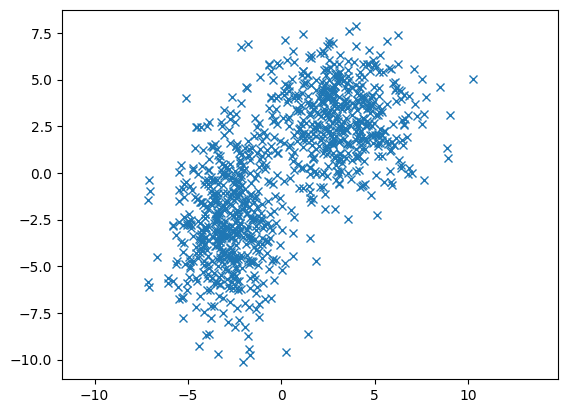

In [51]:
seed = 42
np.random.seed(seed)

mean1 = [3, 3]
cov1 = [[-5, 0], [0, -4]]
points1 = np.random.multivariate_normal(mean1, cov1, 500) # so, in a row: [x, y]
points1 = np.concatenate((points1, np.ones((500, 1))), axis=1)

mean2 = [-3, -3]
cov2 = [[2, 0], [0, 7]]
points2 = np.random.multivariate_normal(mean2, cov2, 500)
points2 = np.concatenate((points2, np.array([[2]] * 500)), axis=1)

points_c = np.concatenate((points1, points2)) # axis 0 concatenate data vertically

np.random.shuffle(points_c)

x = points_c[:,0] # extract first column
y = points_c[:,1]

plt.plot(x, y, 'x')
plt.axis('equal')
plt.show()

np.savetxt("data.csv", points_c, delimiter=",", header="x,y,label")

In [52]:
def run_simple_k_means(points, r1, r2, alpha, epoch):
    history_centroids_update = []
    history_centroids_epoch = []

    for _ in range(epoch):
        for d in points:
            distance_r1 = np.linalg.norm(d[:2] - r1)
            distance_r2 = np.linalg.norm(d[:2] - r2)

            if distance_r1 < distance_r2:
                r1 = (1 - alpha) * r1 + alpha * d[:2]
            else:
                r2 = (1 - alpha) * r2 + alpha * d[:2]
            history_centroids_update.append((r1.copy(), r2.copy()))

        history_centroids_epoch.append((r1.copy(), r2.copy()))

    return history_centroids_update, history_centroids_epoch

def plot_centroids_history(points, history_centroids_update, history_centroids_epoch):
    ax1 = ax2 = None
    if history_centroids_update and history_centroids_epoch:
        _, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    else:
        _, ax1 = plt.subplots(figsize=(7, 6))
        ax2 = ax1

    # Plot 1: Centroid updates
    if history_centroids_update:
        ax1.plot(points[:, 0], points[:, 1], 'x', label='Data points')
        ax1.set_aspect('equal', adjustable='box')
        ax1.set_title('Centroid Updates')

        for i, (r1, r2) in enumerate(history_centroids_update):
            if i % 10 == 0:
                ax1.plot(r1[0], r1[1], 'go', markersize=10,
                        label='R1 Update' if i == 0 else None)
                ax1.plot(r2[0], r2[1], 'yo', markersize=10,
                        label='R2 Update' if i == 0 else None)

        ax1.legend()

    # Plot 2: Centroid positions after each epoch
    if history_centroids_epoch:
        ax2.plot(points[:, 0], points[:, 1], 'x', label='Data points')
        ax2.set_aspect('equal', adjustable='box')
        ax2.set_title('Centroids After Each Epoch')

        for i, (r1, r2) in enumerate(history_centroids_epoch):
            ax2.plot(r1[0], r1[1], 'ro', markersize=10,
                    label='R1 Epoch' if i == 0 else None)
            ax2.plot(r2[0], r2[1], 'bo', markersize=10,
                    label='R2 Epoch' if i == 0 else None)

        ax2.legend()

    plt.tight_layout()
    plt.show()


In [53]:
r1_i, r2_i = np.random.choice(points_c.shape[0], 2, replace=False)

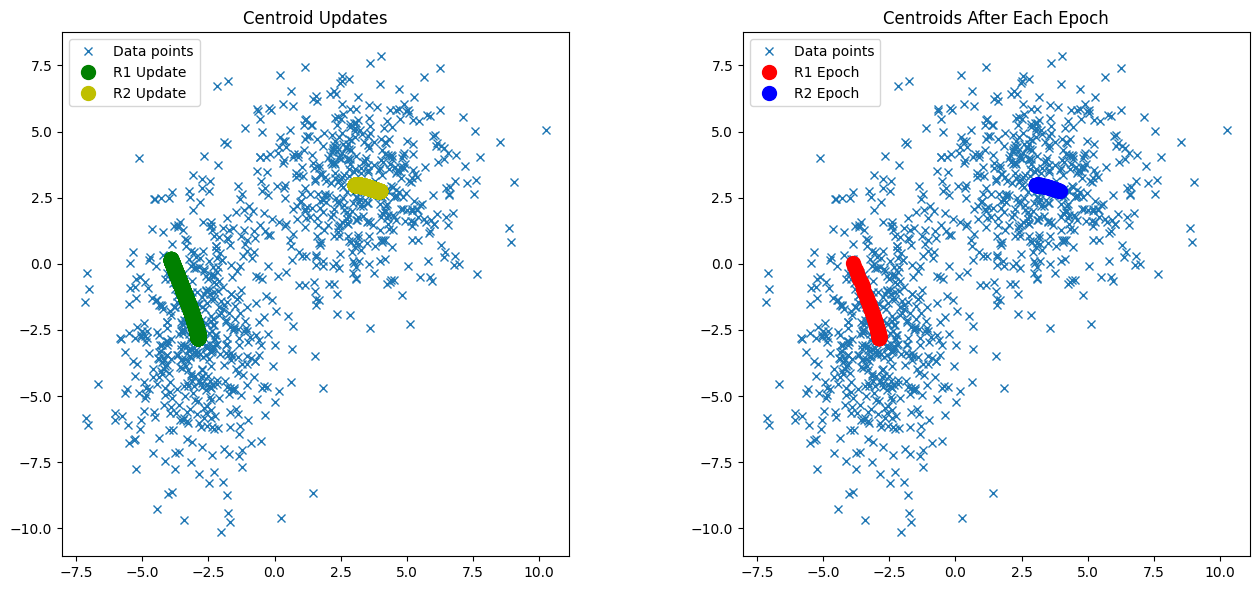

In [54]:
r1 = points_c[r1_i][:2].copy()
r2 = points_c[r2_i][:2].copy()

epoch = 100
alpha = 10e-5

history_centroids_update, history_centroids_epoch = run_simple_k_means(points_c, r1, r2, alpha, epoch)

plot_centroids_history(points_c, history_centroids_update, history_centroids_epoch)

For $\alpha = 10^{-5}$ and $epoch = 10$, we observed that centroids are not ending up in the position they should be (for $r1\_actual = (-3, -3)$ and $r2\_actual = (3, 3)$). This is because the learning rate is too small, and epoch is too low within the learning rate.

We can try to increase the epoch to $100$ and keep the learning rate the same. This will allow the centroids to move more towards their actual positions. But it can be computationally expensive.

---

On the other hand, we can try to increase learning rate to $10^{-3}$ and keep the epoch to $10$. We will be getting exactly the same result as the previous case ($\alpha = 10^{-5}$ and $epoch = 100$). And, this operation may faster than the previous case.



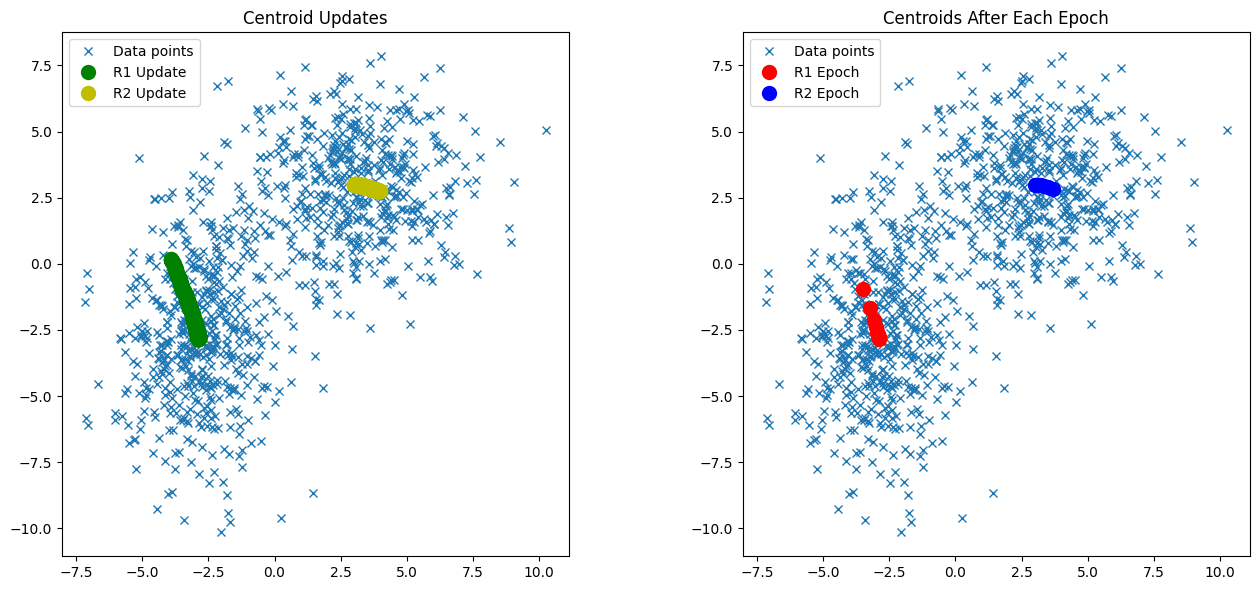

In [55]:
r1 = points_c[r1_i][:2].copy()
r2 = points_c[r2_i][:2].copy()

epoch = 10
alpha = 10e-4

history_centroids_update, history_centroids_epoch = run_simple_k_means(points_c, r1, r2, alpha, epoch)

plot_centroids_history(points_c, history_centroids_update, history_centroids_epoch)

So, we can conclude that, we can either increase the epoch or increase the learning rate to get the same result. But, increasing the learning rate is more efficient than increasing the epoch. Since, each epoch contains a computationally expensive operations.

In [56]:
def run_simple_k_means_v2(points, r1, r2, alpha, epoch):
    history_centroids_epoch = []

    for _ in range(epoch):
        d1 = np.zeros(2)
        d2 = np.zeros(2)

        for d in points:
            distance_r1 = np.linalg.norm(d[:2] - r1)
            distance_r2 = np.linalg.norm(d[:2] - r2)

            if distance_r1 < distance_r2:
                d1 += d[:2] - r1
            else:
                d2 += d[:2] - r2

        r1 += (alpha / len(points)) * d1
        r2 += (alpha / len(points)) * d2
        history_centroids_epoch.append((r1.copy(), r2.copy()))

    return history_centroids_epoch

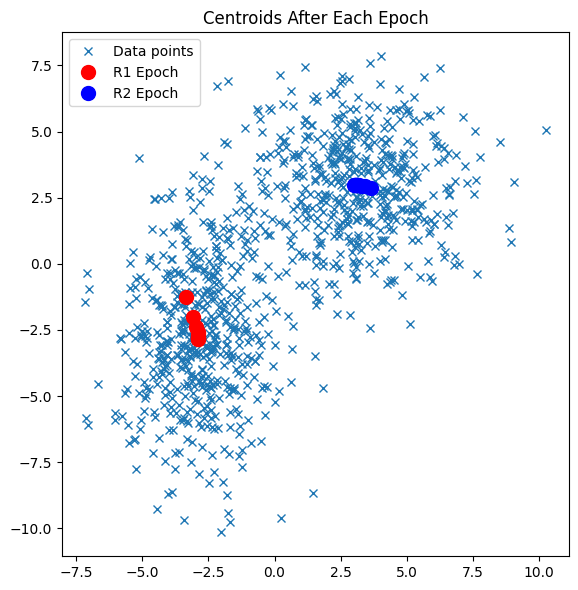

In [57]:
r1 = points_c[r1_i][:2].copy()
r2 = points_c[r2_i][:2].copy()

epoch = 10
alpha = 10e-1

history_centroids_epoch = run_simple_k_means_v2(points_c, r1, r2, alpha, epoch)

plot_centroids_history(points_c, [], history_centroids_epoch)

We observed that this approach requires more epochs or a higher learning rate to converge toward the actual cluster centers. Therefore, we can increase the learning rate to $10^{-1}$ while keeping the number of epochs at $10$. This allows the centroids to move closer to their expected positions within fewer epochs.

When compared to the previous charts, the final positions of the centroids are approximately identical. However, the paths they follow are different. This is mainly because the batch approach accumulates the differences and updates the centroids only once per epoch, whereas the previous approach updates them after processing each data point. Additionally, increasing the learning rate allows the centroids to move faster toward their expected positions.

Therefore, we can conclude that increasing either the number of epochs or the learning rate can improve convergence. Increasing the learning rate can be more computationally efficient because it may reduce the number of epochs required, and each epoch involves processing the entire dataset. However, the learning rate should be chosen carefully, as excessively high values may lead to unstable updates or overshooting.

In [58]:
def plot_centroids_history_v2(points, history_centroids_update, history_centroids_epoch):
    if not history_centroids_update and not history_centroids_epoch:
        return

    if history_centroids_update and history_centroids_epoch:
        _, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    else:
        _, ax1 = plt.subplots(figsize=(7, 6))
        ax2 = ax1

    def plot_points(ax, r1, r2):
        # Calculate distances to final centroids
        d1 = np.linalg.norm(points[:, :2] - r1, axis=1)
        d2 = np.linalg.norm(points[:, :2] - r2, axis=1)

        closest = np.where(d1 < d2, 1, 2)
        labels = points[:, 2]

        colors = {
            (1, 1): 'green',
            (1, 2): 'red',
            (2, 1): 'blue',
            (2, 2): 'yellow'
        }

        for (centroid, label), color in colors.items():
            mask = (closest == centroid) & (labels == label)

            ax.scatter(
                points[mask, 0],
                points[mask, 1],
                c=color,
                marker='x',
                s=20,
                label=f'R{centroid}, Label {label}'
            )

        ax.set_aspect('equal', adjustable='box')

    # Plot 1: Centroid updates
    if history_centroids_update:
        r1, r2 = history_centroids_update[-1]
        plot_points(ax1, r1, r2)
        ax1.set_title('Centroid Updates')

        for i, (r1, r2) in enumerate(history_centroids_update):
            if i % 10 == 0:
                ax1.plot(r1[0], r1[1], 'go', markersize=10,
                         label='R1 Update' if i == 0 else None)
                ax1.plot(r2[0], r2[1], 'yo', markersize=10,
                         label='R2 Update' if i == 0 else None)

        ax1.legend()

    # Plot 2: Centroid positions after each epoch
    if history_centroids_epoch:
        r1, r2 = history_centroids_epoch[-1]
        plot_points(ax2, r1, r2)
        ax2.set_title('Centroids After Each Epoch')

        for i, (r1, r2) in enumerate(history_centroids_epoch):
            ax2.plot(r1[0], r1[1], 'ro', markersize=10,
                     label='R1 Epoch' if i == 0 else None)
            ax2.plot(r2[0], r2[1], 'bo', markersize=10,
                     label='R2 Epoch' if i == 0 else None)

        ax2.legend()

    plt.tight_layout()
    plt.show()

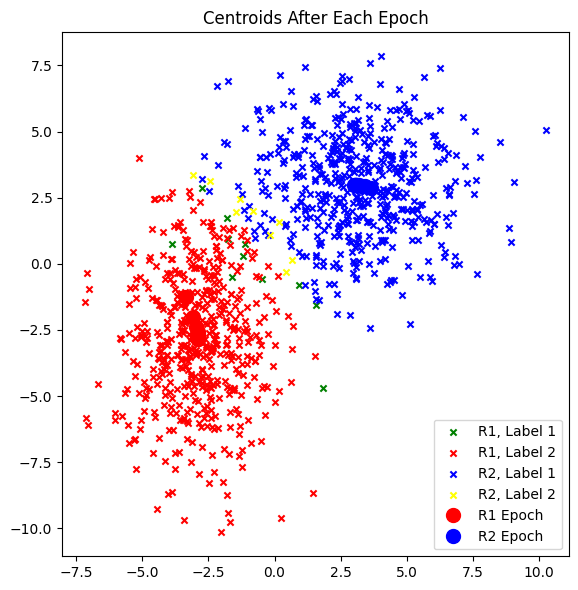

In [59]:
r1 = points_c[r1_i][:2].copy()
r2 = points_c[r2_i][:2].copy()

epoch = 10
alpha = 10e-1

history_centroids_epoch = run_simple_k_means_v2(points_c, r1, r2, alpha, epoch)

plot_centroids_history_v2(points_c, [], history_centroids_epoch)

As we can see from the above chart, all 4 types of points appear: besides R1, Label 1 and R2, Label 2, there are also points that are closer to the representative of the other distribution (R1, Label 2 and R2, Label 1). This is expected, because the two distributions were generated with a small overlap. K-Means assigns each point only by its distance to $r1$ and $r2$, so the boundary between the two clusters is the line equidistant to both representatives. Points from the tails of one distribution that cross this line are assigned to the other cluster, even though they were generated by a different distribution.

In [60]:
n_trials = 30
epoch = 10
alpha = 10e-4

final_r1 = []
final_r2 = []
trials_history = []  # (initial r1, initial r2, history per epoch) for each trial

for t in range(n_trials):
    # New random initialization for each trial
    rng = np.random.default_rng(seed + t)
    i1, i2 = rng.choice(points_c.shape[0], 2, replace=False)
    r1 = points_c[i1][:2].copy()
    r2 = points_c[i2][:2].copy()

    _, history_centroids_epoch = run_simple_k_means(points_c, r1, r2, alpha, epoch)
    trials_history.append((points_c[i1][:2].copy(), points_c[i2][:2].copy(), history_centroids_epoch))
    r1, r2 = history_centroids_epoch[-1]
    final_r1.append(r1)
    final_r2.append(r2)

final_r1 = np.array(final_r1)
final_r2 = np.array(final_r2)

# Group final representatives by the cluster they ended up in (r1/r2 may swap between trials)
finals = np.concatenate((final_r1, final_r2))
top_right = finals[finals[:, 0] > 0]
bottom_left = finals[finals[:, 0] <= 0]

print(f"Top-right cluster:   mean = {top_right.mean(axis=0)}, std = {top_right.std(axis=0)}")
print(f"Bottom-left cluster: mean = {bottom_left.mean(axis=0)}, std = {bottom_left.std(axis=0)}")
print(f"Trials where r1 ended in the top-right cluster: {np.sum(final_r1[:, 0] > 0)} / {n_trials}")

Top-right cluster:   mean = [2.94154371 2.95563344], std = [0.14623297 0.07482605]
Bottom-left cluster: mean = [-2.8960659 -2.9359158], std = [0.04754614 0.22982272]
Trials where r1 ended in the top-right cluster: 19 / 30


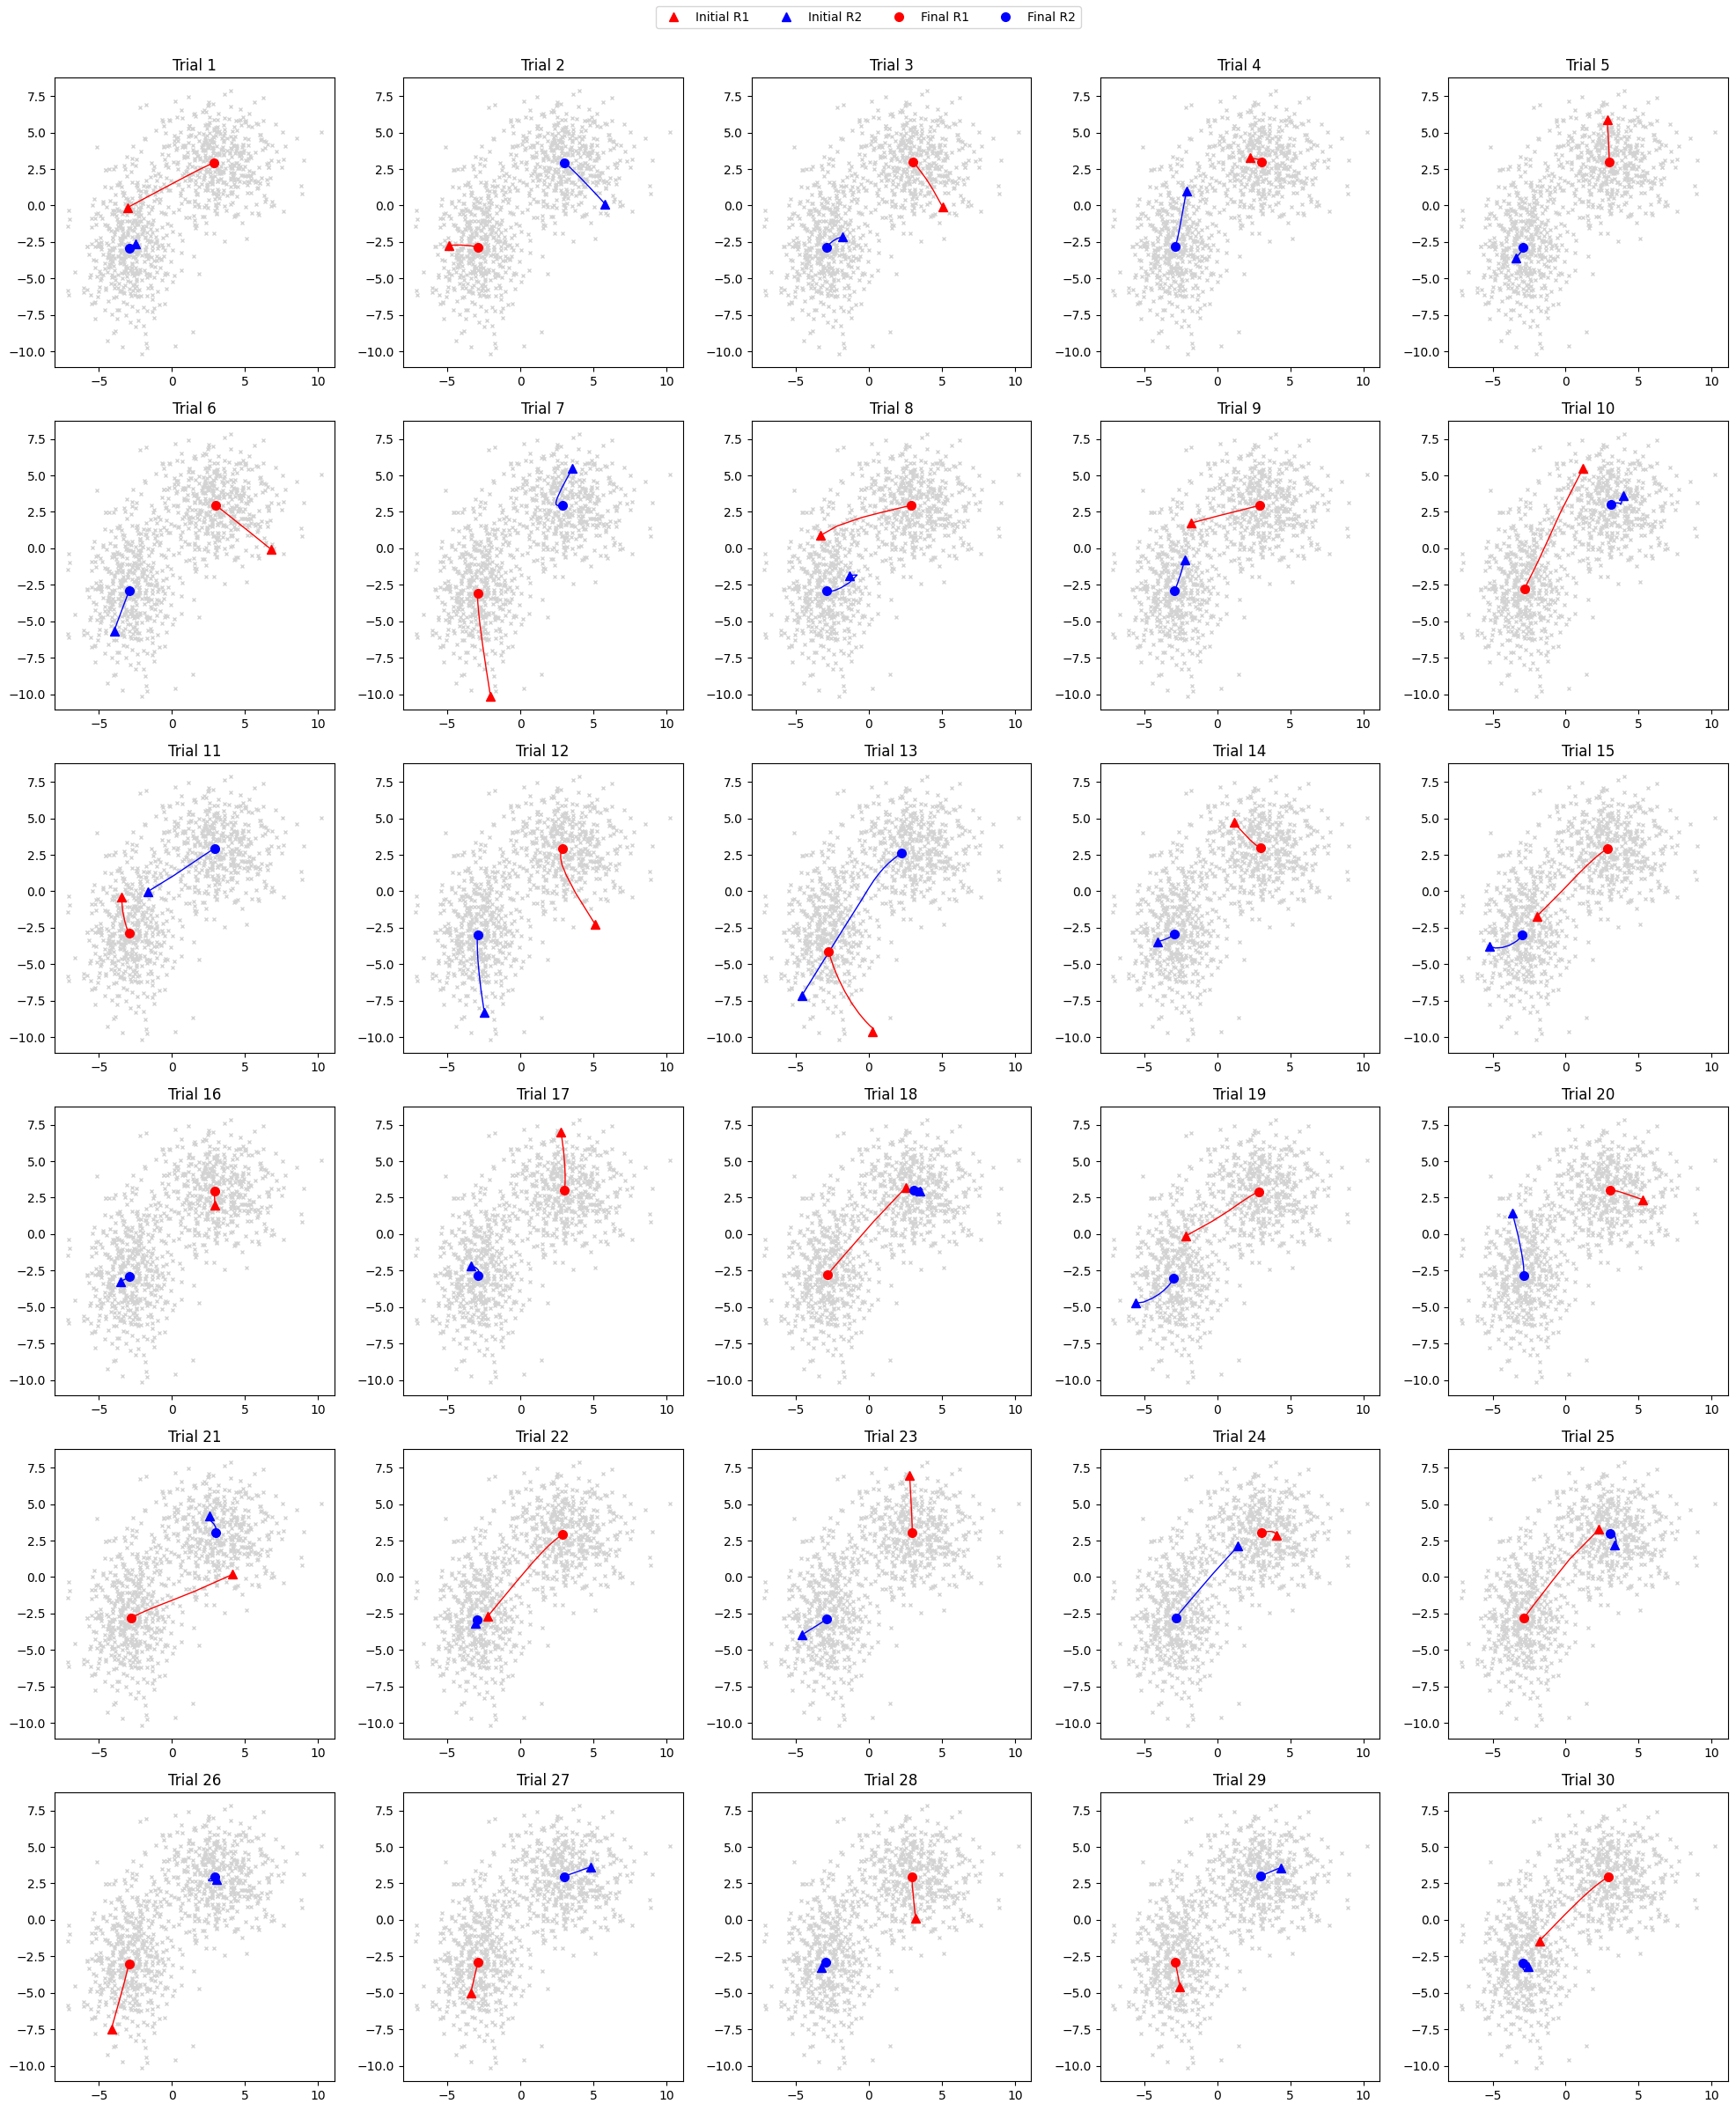

In [61]:
n_cols = 5
n_rows = int(np.ceil(n_trials / n_cols))
_, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

for t, (ax, (r1_init, r2_init, history)) in enumerate(zip(axes.flat, trials_history)):
    r1_path = np.array([r1 for r1, _ in history])
    r2_path = np.array([r2 for _, r2 in history])

    ax.plot(points_c[:, 0], points_c[:, 1], 'x', color='lightgray', markersize=3)

    # Path from the initial point to the end of each epoch
    ax.plot(*np.vstack((r1_init, r1_path)).T, 'r-', linewidth=1)
    ax.plot(*np.vstack((r2_init, r2_path)).T, 'b-', linewidth=1)

    ax.plot(*r1_init, 'r^', markersize=7, label='Initial R1')
    ax.plot(*r2_init, 'b^', markersize=7, label='Initial R2')
    ax.plot(*r1_path[-1], 'ro', markersize=7, label='Final R1')
    ax.plot(*r2_path[-1], 'bo', markersize=7, label='Final R2')

    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f'Trial {t + 1}')

# Hide unused axes if n_trials is not a multiple of n_cols
for ax in axes.flat[n_trials:]:
    ax.axis('off')

handles, labels = axes.flat[0].get_legend_handles_labels()
plt.figlegend(handles, labels, loc='upper center', ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

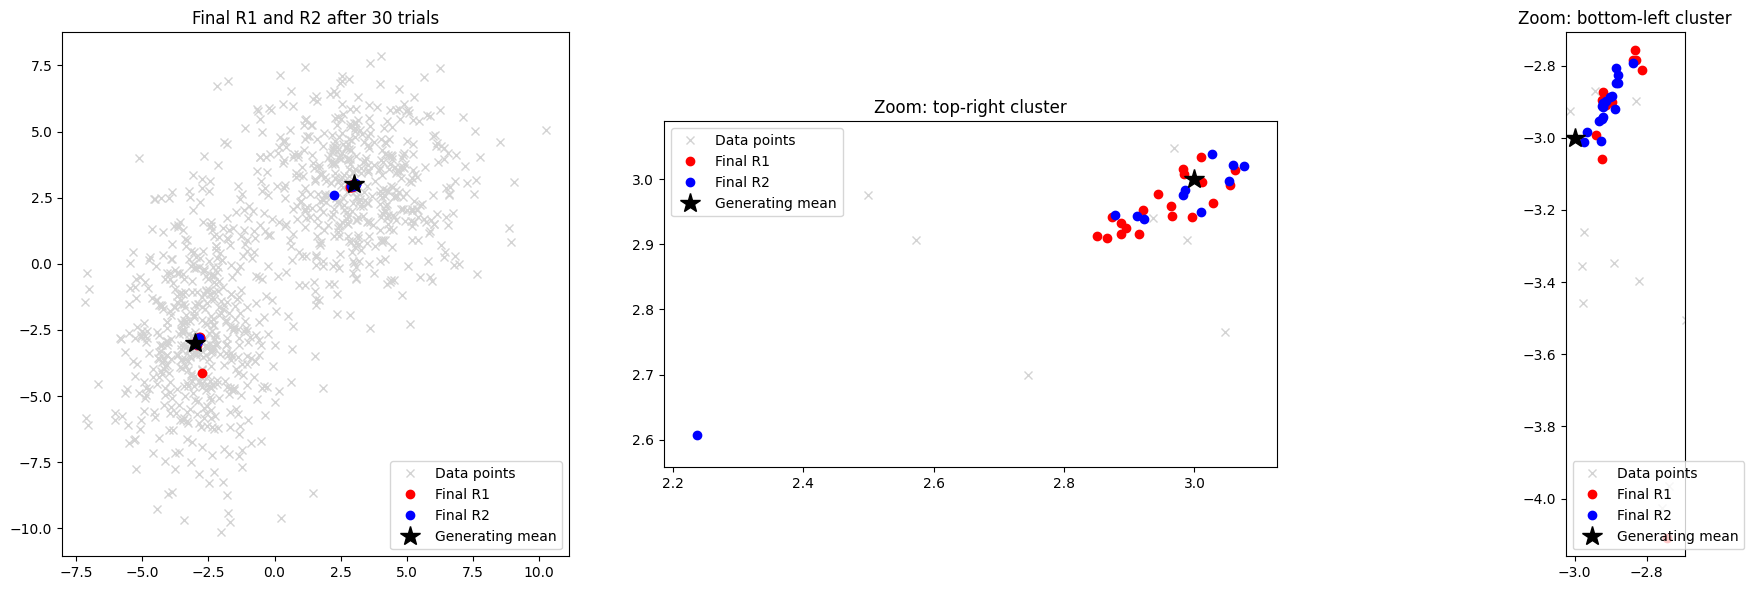

In [62]:
def plot_final_centroids(ax, title, limits=None):
    ax.plot(points_c[:, 0], points_c[:, 1], 'x', color='lightgray', label='Data points')
    ax.plot(final_r1[:, 0], final_r1[:, 1], 'ro', markersize=6, label='Final R1')
    ax.plot(final_r2[:, 0], final_r2[:, 1], 'bo', markersize=6, label='Final R2')
    ax.plot(*mean1, 'k*', markersize=15, label='Generating mean')
    ax.plot(*mean2, 'k*', markersize=15)

    if limits is not None:
        ax.set_xlim(limits[0])
        ax.set_ylim(limits[1])

    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title)
    ax.legend()

def zoom_limits(cluster, margin=0.05):
    lo = cluster.min(axis=0) - margin
    hi = cluster.max(axis=0) + margin
    return (lo[0], hi[0]), (lo[1], hi[1])

_, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

plot_final_centroids(ax1, f'Final R1 and R2 after {n_trials} trials')
plot_final_centroids(ax2, 'Zoom: top-right cluster', zoom_limits(top_right))
plot_final_centroids(ax3, 'Zoom: bottom-left cluster', zoom_limits(bottom_left))

plt.tight_layout()
plt.show()

In the full view, the final representatives of all 30 trials collapse onto two spots, one near each generating mean $(3, 3)$ and $(-3, -3)$. The zoomed views show that they are not identical: they form a small cloud around each mean (spread of roughly $0.1$), because the online rule keeps moving the representative with every example and the final value depends on the random initialization and on the last examples seen.

The colors are mixed in both clusters: $r1$ ends in the top-right cluster in about half of the trials and in the bottom-left cluster in the rest. The algorithm does not know which cluster is "1" and which is "2"; the name of the representative only depends on which random point was picked first. So the representatives find the cluster centers, but the mapping between $r1$/$r2$ and the labels is arbitrary.

A few trials can end noticeably further from the mean (outliers in the zoomed plots). This shows that, with a fixed number of epochs and a constant $\alpha$, the result still depends on the initialization (e.g. when both initial points are picked from the same cluster, one representative first has to travel to the other cluster).